## 1. Tải và kết nối cơ sở dữ liệu

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import requests
import pathlib

# Tải file Chinook.db nếu chưa tồn tại
url = "https://storage.googleapis.com/benchmarks-artifacts/chinook/Chinook.db"
local_path = pathlib.Path("Chinook.db")

if not local_path.exists():
    response = requests.get(url, timeout=60)
    if response.status_code == 200:
        local_path.write_bytes(response.content)
        print("Đã tải xuống Chinook.db")
    else:
        print(f"Lỗi tải file: {response.status_code}")
else:
    print("File Chinook.db đã tồn tại.")

# Kết nối đến database
conn = sqlite3.connect('Chinook.db')
cursor = conn.cursor()



File Chinook.db đã tồn tại.


## 2. Khám phá lược đồ cơ sở dữ liệu

In [ ]:
# Lấy danh sách tất cả các bảng
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
tables = cursor.fetchall()
print("Các bảng trong database:")
for table in tables:
    print(f"- {table[0]}")

Các bảng trong database:
- Album
- Artist
- Customer
- Employee
- Genre
- Invoice
- InvoiceLine
- MediaType
- Playlist
- PlaylistTrack
- Track


<b>Các mối quan hệ chính:</b>

- Artist (1) -> (N) Album -> (N) Track

- Track (1) -> (N) InvoiceLine -> (N) Invoice

- Customer (1) -> (N) Invoice

- Employee (1) -> (N) Customer (qua SupportRepId)

- Employee tự tham chiếu (qua ReportsTo để xác định cấp trên)

Câu hỏi 1: 10 bản nhạc bán chạy nhất

## 3. Viết các truy vấn SQL

In [ ]:
query_top_tracks = """
SELECT
    t.Name AS TrackName,
    ar.Name AS ArtistName,
    SUM(il.Quantity) AS TotalSold
FROM InvoiceLine il
JOIN Track t ON il.TrackId = t.TrackId
JOIN Album al ON t.AlbumId = al.AlbumId
JOIN Artist ar ON al.ArtistId = ar.ArtistId
GROUP BY t.TrackId
ORDER BY TotalSold DESC
LIMIT 10;
"""

df_top_tracks = pd.read_sql_query(query_top_tracks, conn)
print(df_top_tracks)

                   TrackName            ArtistName  TotalSold
0          Balls to the Wall                Accept          2
1           Inject The Venom                 AC/DC          2
2                 Snowballed                 AC/DC          2
3                   Overdose                 AC/DC          2
4            Deuces Are Wild             Aerosmith          2
5             Not The Doctor     Alanis Morissette          2
6          Por Causa De Você  Antônio Carlos Jobim          2
7  Welcome Home (Sanitarium)          Apocalyptica          2
8                  Snowblind         Black Sabbath          2
9                 Cornucopia         Black Sabbath          2


Câu hỏi 2: Quốc gia tạo ra nhiều doanh thu nhất

In [ ]:
query_top_country = """
SELECT
    c.Country,
    SUM(i.Total) AS TotalRevenue
FROM Invoice i
JOIN Customer c ON i.CustomerId = c.CustomerId
GROUP BY c.Country
ORDER BY TotalRevenue DESC
LIMIT 1;
"""

df_top_country = pd.read_sql_query(query_top_country, conn)
print(df_top_country)

  Country  TotalRevenue
0     USA        523.06


Câu hỏi 3: Nhân viên kinh doanh có hiệu suất cao nhất

In [ ]:
query_top_employee = """
SELECT
    e.FirstName || ' ' || e.LastName AS EmployeeName,
    e.Title,
    SUM(i.Total) AS TotalSales
FROM Invoice i
JOIN Customer c ON i.CustomerId = c.CustomerId
JOIN Employee e ON c.SupportRepId = e.EmployeeId
GROUP BY e.EmployeeId
ORDER BY TotalSales DESC
LIMIT 1;
"""

df_top_employee = pd.read_sql_query(query_top_employee, conn)
print(df_top_employee)

   EmployeeName                Title  TotalSales
0  Jane Peacock  Sales Support Agent      833.04


## 4. Trực quan hóa kết quả

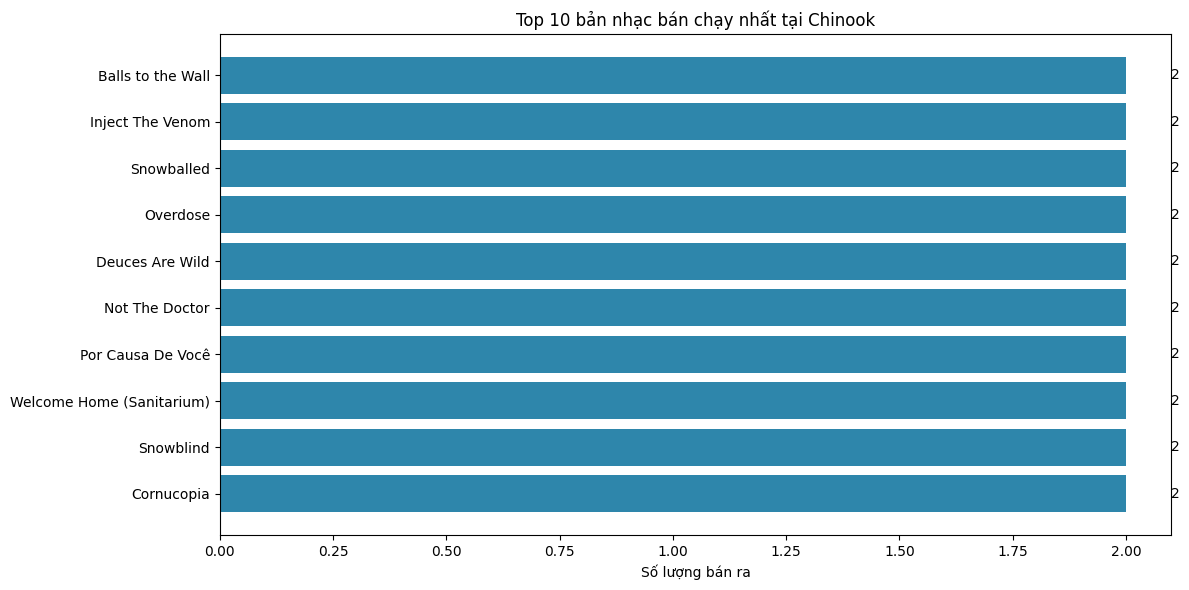

In [ ]:
plt.figure(figsize=(12, 6))
bars = plt.barh(df_top_tracks['TrackName'], df_top_tracks['TotalSold'], color='#2E86AB')

# Thêm nhãn giá trị lên mỗi cột
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2,
             f'{int(width)}', va='center', fontsize=10)

plt.xlabel('Số lượng bán ra')
plt.title('Top 10 bản nhạc bán chạy nhất tại Chinook')
plt.gca().invert_yaxis()  # Đảo ngược để bản nhạc bán chạy nhất ở trên cùng
plt.tight_layout()
plt.show()

## 5. Đóng kết nối

In [ ]:
conn.close()